# Introduction to Reccurent Neural Networks (RNNs)

This practical session is dedicated to a special kind of multi-layer neural networks called recurrent neural networks (RNNs).

You will create and train a simple character-level Recurrent Neural Network (RNN) to classify words. In this approach, the RNN processes each word one character at a time, producing a prediction and an updated hidden state at every step. The hidden state is carried forward to the next character, and the final output determines the wordâ€™s class.

Youâ€™ll use several thousand surnames from 18 different languages and train the network to identify the language of a name based solely on its spelling.

### Configuring Torch

Set the default device for computations to use CPU:

In [1]:
import torch

# Check if CUDA is available
device = torch.device('cpu')
if torch.mps.is_available():
    device = torch.device('mps')

torch.set_default_device(device)
print(f"Using device = {torch.get_default_device()}")

Using device = mps:0


### Preparing the Data

Download and extract the data to the current directory. Inside data/names are 18 text files named [Language].txt, each containing one name per line. Most names are romanized but need conversion from Unicode to ASCII.

We first define the set of allowed characters and convert names from Unicode to ASCII:

In [2]:
import string
import unicodedata

# We can use "_" to represent an out-of-vocabulary character, that is, any character we are not handling in our model
allowed_characters = string.ascii_letters + " .,;'" + "_"
n_letters = len(allowed_characters)

# Turn a Unicode string to plain ASCII, thanks to https://stackoverflow.com/a/518232/2809427
def unicodeToAscii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
        and c in allowed_characters
    )

This example shows how to convert a Unicode name into plain ASCII, making the input simpler for the network.

In [3]:
print (f"converting 'ÅšlusÃ rski' to {unicodeToAscii('ÅšlusÃ rski')}")

converting 'ÅšlusÃ rski' to AslusA rski


### Converting Names to Tensors

Each character is represented by a one-hot vector of size <1 x num_chars>. A word is a sequence of these vectors with shape <word_length x 1 x num_chars>. The extra dimension accounts for batch size (here, batch = 1).

In [4]:
# Find letter index from all_letters, e.g. "a" = 0
def letterToIndex(letter):
    # return our out-of-vocabulary character if we encounter a letter unknown to our model
    if letter not in allowed_characters:
        return allowed_characters.find("_")
    else:
        return allowed_characters.find(letter)

# Turn a line into a <line_length x 1 x n_letters>,
# or an array of one-hot letter vectors
def lineToTensor(line):
    tensor = torch.zeros(len(line), 1, n_letters)
    for li, letter in enumerate(line):
        tensor[li][0][letterToIndex(letter)] = 1
    return tensor

Here are some examples of how to use lineToTensor() for a single and multiple character string.

In [5]:
print (f"The letter 'a' becomes {lineToTensor('a')}") #notice that the first position in the tensor = 1
print (f"The name 'Ahn' becomes {lineToTensor('Ahn')}") #notice 'A' sets the 27th index to 1

The letter 'a' becomes tensor([[[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]]], device='mps:0')
The name 'Ahn' becomes tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0

### Creating the Dataset

We organize all names into a dataset, storing both the raw text and tensor representations:

In [6]:
from io import open
import glob
import os
import time

import torch
from torch.utils.data import Dataset

class NamesDataset(Dataset):

    def __init__(self, data_dir):
        self.data_dir = data_dir #for provenance of the dataset
        self.load_time = time.localtime #for provenance of the dataset
        labels_set = set() #set of all classes

        self.data = []
        self.data_tensors = []
        self.labels = []
        self.labels_tensors = []

        #read all the ``.txt`` files in the specified directory
        text_files = glob.glob(os.path.join(data_dir, '*.txt'))
        for filename in text_files:
            label = os.path.splitext(os.path.basename(filename))[0]
            labels_set.add(label)
            lines = open(filename, encoding='utf-8').read().strip().split('\n')
            for name in lines:
                self.data.append(name)
                self.data_tensors.append(lineToTensor(name))
                self.labels.append(label)

        #Cache the tensor representation of the labels
        self.labels_uniq = list(labels_set)
        for idx in range(len(self.labels)):
            temp_tensor = torch.tensor([self.labels_uniq.index(self.labels[idx])], dtype=torch.long)
            self.labels_tensors.append(temp_tensor)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        data_item = self.data[idx]
        data_label = self.labels[idx]
        data_tensor = self.data_tensors[idx]
        label_tensor = self.labels_tensors[idx]

        return label_tensor, data_tensor, data_label, data_item

We can now load our sample data into the NamesDataset class.

In [7]:
alldata = NamesDataset("data/names")
print(f"loaded {len(alldata)} items of data")
print(f"example = {alldata[0]}")

loaded 20074 items of data
example = (tensor([17], device='mps:0'), tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]],

        [[0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]]], device='mps:0'), 'Czech', 'Abl')


The dataset object makes it straightforward to divide the data into training and testing sets. In this example, we use an 80/20 split, although torch.utils.data provides additional utilities for splitting. We also specify a generator to ensure the split uses the same device configured for PyTorch.

In [8]:
train_set, test_set = torch.utils.data.random_split(alldata, [.80, .20], generator=torch.Generator(device=device).manual_seed(2024))

print(f"train examples = {len(train_set)}, validation examples = {len(test_set)}")

train examples = 16060, validation examples = 4014


### Defining the Network

Before the introduction of autograd, building a recurrent neural network in Torch required manually cloning a layerâ€™s parameters across multiple timesteps. Each layer managed its own hidden state and gradients, whereas now these are fully handled by the computational graph. This allows RNNs to be implemented more cleanly, almost like standard feed-forward networks.

The CharRNN class implements a character-level RNN with three main components. First, it uses nn.RNN to handle the recurrent computations. Next, a linear layer maps the hidden states to the output space. Finally, a log-softmax function produces probability scores for classification. Using nn.RNN not only simplifies the implementation but also improves performance through features like cuDNN-accelerated kernels, compared to manually constructing each layer with nn.Linear.

Create a one layer RNN with a Softmax activation layer as its otuput. Do not forget to create the forward function. All parameters should be given by the user, there are no predefined values.

In [13]:
import torch.nn as nn
import torch.nn.functional as F

class CharRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(CharRNN, self).__init__()
        self.hidden_size = hidden_size
        self.rnn = nn.RNN(input_size, hidden_size)
        self.fc = nn.Linear(hidden_size, output_size)
        self.log_softmax = nn.LogSoftmax(dim=1)

    def forward(self, input_tensor):
        output, _ = self.rnn(input_tensor)
        output = self.fc(output[-1])    # Take the last output
        output = self.log_softmax(output)

        return output

We can then instantiate an RNN with 58 input units, 128 hidden units, and 18 output classes:


In [22]:
char_rnn = CharRNN(n_letters, 128, len(alldata.labels_uniq)).to(device)
model_name = "simple_char_rnn"
char_rnn

CharRNN(
  (rnn): RNN(58, 128)
  (fc): Linear(in_features=128, out_features=18, bias=True)
  (log_softmax): LogSoftmax(dim=1)
)

Next, we feed our tensor into the RNN to generate a predicted output. We then use the helper function label_from_output to convert this output into a readable class label.

In [ ]:
def label_from_output(output, output_labels):
    _, top_i = output.topk(1)
    label_i = top_i[0].item()

    return output_labels[label_i], label_i

input = lineToTensor('Albert')
output = char_rnn(input)    # This is equivalent to ``output = rnn.forward(input)``
print(output)
print(label_from_output(output, alldata.labels_uniq))

tensor([[-2.9520, -2.8764, -2.9769, -3.0355, -2.8889, -2.7081, -2.8946, -2.8596,
         -2.8541, -2.9517, -2.7705, -2.8132, -2.8793, -2.9469, -2.9812, -2.8935,
         -2.8472, -2.9525]], device='mps:0', grad_fn=<LogSoftmaxBackward0>)
('English', 5)


### Training the Network

Training the network simply involves presenting it with many examples, letting it make predictions, and correcting it when itâ€™s wrong. We accomplish this by defining a train() function that updates the model using minibatches. Like other neural networks, RNNs can be trained in a similar way. In this batched training approach, the loop iterates over each item in a batch to calculate its loss before updating the modelâ€™s weights. This process is repeated for the specified number of epochs.

Create a train function for your CharRNN with optimizer SGD. Create

In [32]:
import os
import time
import random
import json
import torch
import torch.nn as nn
import numpy as np

def train(rnn, training_data, model_name, n_epoch=10, n_batch_size=64, report_every=1,
          learning_rate=0.2, criterion=nn.NLLLoss(), device=None, checkpoint_dir='checkpoints'):
    """
    Treina a RNN com minibatches, suporte a GPU/CPU e salvamento automático de checkpoints e histórico por modelo.
    """
    # 1. Device configuration
    if device is None:
        if torch.cuda.is_available():
            device = torch.device('cuda')
        elif torch.backends.mps.is_available():
            device = torch.device('mps')
        else:
            device = torch.device('cpu')

    rnn.to(device)

    # Defines and create the model directory for saving checkpoints and loss history
    model_dir = os.path.join(checkpoint_dir, model_name)
    os.makedirs(model_dir, exist_ok=True)

    current_loss = 0
    all_losses = []
    best_loss = float('inf')

    optimizer = torch.optim.SGD(rnn.parameters(), lr=learning_rate)
    start = time.time()
    print(f"Training [{model_name}] on dataset (n = {len(training_data)}) using device: {device}")

    # 2. Training loop
    for iter in range(1, n_epoch + 1):
        rnn.train()

        indices = list(range(len(training_data)))
        random.shuffle(indices)

        batches = [
            [training_data[i] for i in indices[k : k + n_batch_size]]
            for k in range(0, len(indices), n_batch_size)
        ]

        for batch in batches:
            optimizer.zero_grad()
            batch_loss = 0

            for label_tensor, data_tensor, _, _ in batch:
                data_tensor = data_tensor.to(device)
                label_tensor = label_tensor.to(device)

                output = rnn(data_tensor)
                batch_loss += criterion(output, label_tensor)

            batch_loss /= len(batch)
            current_loss += batch_loss.item()
            batch_loss.backward()
            optimizer.step()

        epoch_loss = current_loss / len(batches)
        all_losses.append(epoch_loss)

        # 3. Saves the best model checkpoint
        if epoch_loss < best_loss:
            best_loss = epoch_loss
            checkpoint = {
                'epoch': iter,
                'model_state_dict': rnn.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'best_loss': best_loss,
                'all_losses': all_losses
            }
            torch.save(checkpoint, os.path.join(model_dir, 'best_model.pt'))

        # 4. Progress report
        if iter % report_every == 0 or iter == n_epoch:
            elapsed_time = time.time() - start
            print(f"Epoch {iter}/{n_epoch} ({iter / n_epoch:.0%}) | Time: {elapsed_time:.2f}s | Average Loss: {epoch_loss:.4f}")

        current_loss = 0

    # 5. Saves the last checkpoint and the loss history
    last_checkpoint = {
        'epoch': n_epoch,
        'model_state_dict': rnn.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': all_losses[-1],
        'all_losses': all_losses
    }
    torch.save(last_checkpoint, os.path.join(model_dir, 'last_model.pt'))

    with open(os.path.join(model_dir, 'losses.json'), 'w') as f:
        json.dump(all_losses, f)

    print(f"\nTraining complete! Checkpoints saved to '{model_dir}/'")
    return all_losses

We can now train the model on the dataset using minibatches for a set number of epochs. In this example, the number of epochs is reduced to speed up execution, but adjusting these parameters can lead to improved performance.


In [30]:
import os
import time
import torch

# Defines the model name and checkpoint path
model_name = "simple_char_rnn"
checkpoint_dir = 'checkpoints'
checkpoint_path = os.path.join(checkpoint_dir, model_name, 'best_model.pt')

# Defines the device to be used for training and inference
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

# Define as true if you want to ignore the checkpoint and train from scratch
force_train = False

if os.path.exists(checkpoint_path) and not force_train:
    print(f"Checkpoint found at '{checkpoint_path}'. Loading model and loss history...")

    checkpoint = torch.load(checkpoint_path, map_location=device)
    char_rnn.load_state_dict(checkpoint['model_state_dict'])
    char_rnn.to(device)

    all_losses = checkpoint['all_losses']

    print("Model loaded successfully!")
    print(f"Checkpoint epoch: {checkpoint.get('epoch', 'N/A')} | Best Loss: {checkpoint.get('best_loss', 'N/A'):.4f}")

else:
    if force_train:
        print(f"Training forced by user (`force_train = True`). Starting [{model_name}] from scratch...")
    else:
        print(f"No checkpoint found for [{model_name}]. Starting training...")

    start = time.time()

    all_losses = train(
        rnn=char_rnn,
        training_data=train_set,
        model_name=model_name,
        n_epoch=27,
        learning_rate=0.15,
        report_every=3,
        device=device,
        checkpoint_dir=checkpoint_dir
    )

    end = time.time()
    print(f"Training finished in {end - start:.2f}s")

No checkpoint found for [simple_char_rnn]. Starting training...
Training [simple_char_rnn] on dataset (n = 16060) using device: mps
Epoch 3/27 (11%) | Time: 39.65s | Average Loss: 1.0089
Epoch 6/27 (22%) | Time: 78.85s | Average Loss: 0.8755
Epoch 9/27 (33%) | Time: 117.95s | Average Loss: 0.7862
Epoch 12/27 (44%) | Time: 156.98s | Average Loss: 0.7061
Epoch 15/27 (56%) | Time: 196.07s | Average Loss: 0.6391
Epoch 18/27 (67%) | Time: 235.13s | Average Loss: 0.5849
Epoch 21/27 (78%) | Time: 274.11s | Average Loss: 0.5446
Epoch 24/27 (89%) | Time: 313.24s | Average Loss: 0.5013
Epoch 27/27 (100%) | Time: 352.38s | Average Loss: 0.4538

Training complete! Checkpoints saved to 'checkpoints/simple_char_rnn/'
Training finished in 352.38s


### Plotting the Results
Plotting the historical loss from all_losses shows the network learning:

In [35]:
import os
import matplotlib.pyplot as plt

def plot_loss_curve(all_losses, model_name, figures_dir='figures'):
    """
    Plota a curva de perda (loss) ao longo das épocas e salva a imagem.
    """
    model_fig_dir = os.path.join(figures_dir, model_name)
    os.makedirs(model_fig_dir, exist_ok=True)

    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(all_losses) + 1), all_losses, marker='o', color='#1f77b4', linewidth=2, label='Train Loss')

    plt.title(f'Training Loss Curve - {model_name}', fontsize=14, fontweight='bold', pad=12)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss (NLLLoss)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(fontsize=11)
    plt.tight_layout()

    save_path = os.path.join(model_fig_dir, 'loss_curve.png')
    plt.savefig(save_path, dpi=300)
    plt.show()
    print(f"Loss curve saved to '{save_path}'")

### Evaluating the Results

To assess how well the network performs across categories, we create a confusion matrix that shows, for each true language (rows), which language the network predicts (columns). The confusion matrix is computed by passing multiple samples through the `evaluate()` function, which works like `train()` but without performing backpropagation.


In [37]:
import json
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

def evaluate(rnn, testing_data, classes, model_name, device=None,
             figures_dir='figures', checkpoint_dir='checkpoints'):
    """
    Avalia a RNN no conjunto de teste, gera e salva a matriz de confusão anotada
    e exporta as métricas de acurácia global e por classe em JSON.
    """
    # 1. Configuração do dispositivo
    if device is None:
        if torch.cuda.is_available():
            device = torch.device('cuda')
        elif torch.backends.mps.is_available():
            device = torch.device('mps')
        else:
            device = torch.device('cpu')

    rnn.to(device)
    rnn.eval()

    n_classes = len(classes)
    confusion_counts = torch.zeros(n_classes, n_classes)

    # 2. Loop de Avaliação
    with torch.no_grad():
        for i in range(len(testing_data)):
            (label_tensor, text_tensor, label, text) = testing_data[i]

            # Garante que o tensor de entrada esteja no dispositivo correto
            text_tensor = text_tensor.to(device)

            output = rnn(text_tensor)
            guess, guess_i = label_from_output(output, classes)
            label_i = classes.index(label)

            confusion_counts[label_i][guess_i] += 1

    # 3. Cálculo de Métricas
    total_samples = confusion_counts.sum().item()
    correct_predictions = confusion_counts.diag().sum().item()
    overall_accuracy = correct_predictions / total_samples if total_samples > 0 else 0.0

    per_class_samples = confusion_counts.sum(dim=1)
    per_class_correct = confusion_counts.diag()

    # Evita divisão por zero se alguma classe não estiver presente no teste
    per_class_accuracy = {}
    macro_acc_list = []

    for idx, class_name in enumerate(classes):
        samples = per_class_samples[idx].item()
        correct = per_class_correct[idx].item()
        acc = (correct / samples) if samples > 0 else 0.0

        per_class_accuracy[class_name] = round(acc, 4)
        if samples > 0:
            macro_acc_list.append(acc)

    macro_accuracy = float(np.mean(macro_acc_list)) if macro_acc_list else 0.0

    # 4. Salvamento das Métricas em JSON
    metrics_data = {
        'model_name': model_name,
        'overall_accuracy': round(overall_accuracy, 4),
        'macro_accuracy': round(macro_accuracy, 4),
        'total_test_samples': int(total_samples),
        'per_class_accuracy': per_class_accuracy,
        'per_class_samples': {cls: int(per_class_samples[i].item()) for i, cls in enumerate(classes)}
    }

    model_ckpt_dir = os.path.join(checkpoint_dir, model_name)
    os.makedirs(model_ckpt_dir, exist_ok=True)
    metrics_path = os.path.join(model_ckpt_dir, 'metrics.json')

    with open(metrics_path, 'w') as f:
        json.dump(metrics_data, f, indent=4)
    print(f"Metrics saved to '{metrics_path}'")

    # 5. Normalização para Visualização da Matriz de Confusão
    confusion_norm = confusion_counts.clone()
    for i in range(n_classes):
        denom = confusion_norm[i].sum()
        if denom > 0:
            confusion_norm[i] /= denom

    confusion_np = confusion_norm.cpu().numpy()

    # 6. Plotagem e Anotação da Matriz de Confusão
    fig, ax = plt.subplots(figsize=(10, 9))
    cax = ax.imshow(confusion_np, cmap='Blues', vmin=0, vmax=1)
    fig.colorbar(cax, fraction=0.046, pad=0.04)

    # Adiciona rótulos nos eixos
    ax.set_xticks(np.arange(n_classes))
    ax.set_yticks(np.arange(n_classes))
    ax.set_xticklabels(classes, rotation=90, fontsize=10)
    ax.set_yticklabels(classes, fontsize=10)

    ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold', labelpad=10)
    ax.set_ylabel('True Label', fontsize=12, fontweight='bold', labelpad=10)
    ax.set_title(f'Normalized Confusion Matrix - {model_name}\nOverall Acc: {overall_accuracy:.2%}',
                 fontsize=13, fontweight='bold', pad=15)

    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))

    # Anotação numérica em cada célula (exibe porcentagens > 1% para evitar poluição visual)
    for i in range(n_classes):
        for j in range(n_classes):
            val = confusion_np[i, j]
            if val >= 0.01:
                color = "white" if val > 0.5 else "black"
                ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=7.5, fontweight='bold')

    plt.tight_layout()

    model_fig_dir = os.path.join(figures_dir, model_name)
    os.makedirs(model_fig_dir, exist_ok=True)
    matrix_path = os.path.join(model_fig_dir, 'confusion_matrix.png')

    plt.savefig(matrix_path, dpi=300)
    plt.show()
    print(f"Confusion matrix saved to '{matrix_path}'")

    return metrics_data

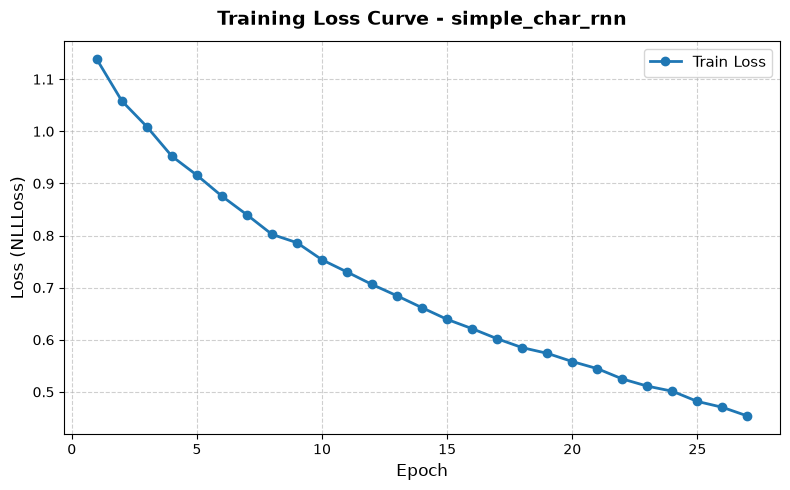

Loss curve saved to 'figures/simple_char_rnn/loss_curve.png'
Metrics saved to 'checkpoints/simple_char_rnn/metrics.json'


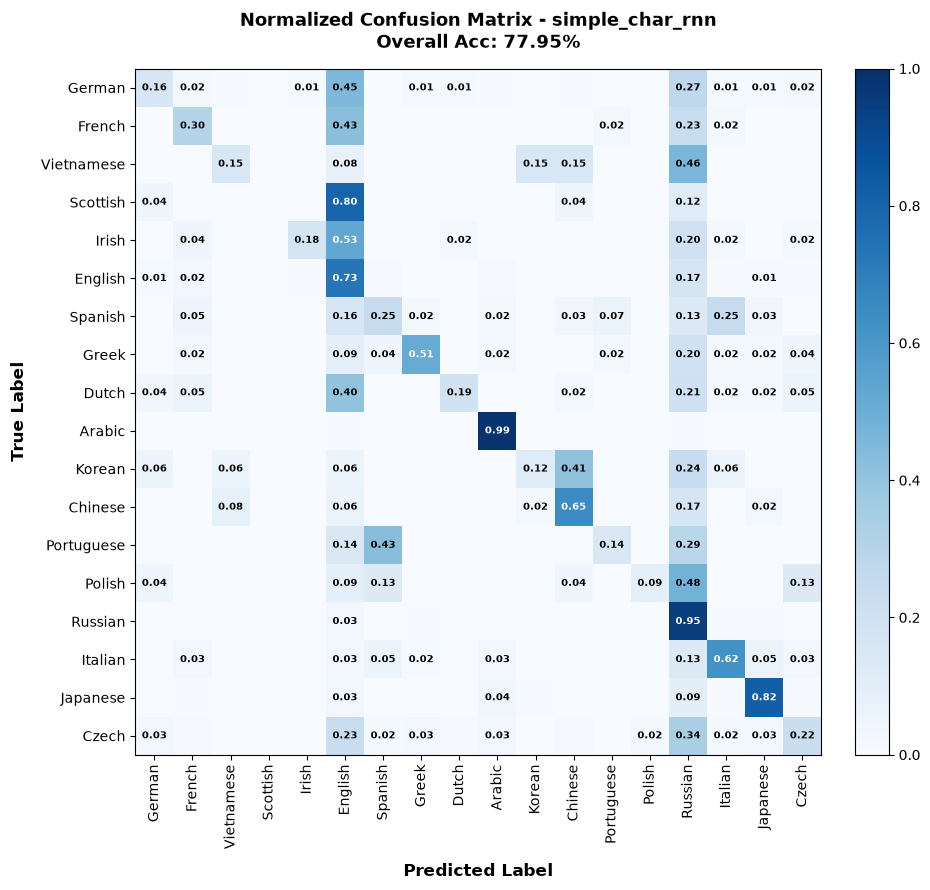

Confusion matrix saved to 'figures/simple_char_rnn/confusion_matrix.png'

--- Evaluation Summary [simple_char_rnn] ---
Overall Accuracy: 77.95%
Macro Accuracy:   39.23%


In [38]:
# 1. Plots and saves the loss curve for the training process
plot_loss_curve(all_losses, model_name=model_name)

# 2. Evaluates the network on the test set, saves the plots and the JSON of metrics
metrics = evaluate(
    rnn=char_rnn,
    testing_data=test_set,
    classes=alldata.labels_uniq,
    model_name=model_name,
    device=device
)

# Main metrics report
print(f"\n--- Evaluation Summary [{model_name}] ---")
print(f"Overall Accuracy: {metrics['overall_accuracy']:.2%}")
print(f"Macro Accuracy:   {metrics['macro_accuracy']:.2%}")

You can identify off-diagonal highlights in the matrix that indicate misclassifications, such as predicting Chinese for Korean or Spanish for Italian. The network performs very well on Greek names but struggles with English, likely due to overlap with other languages.

# Exercises:

<ol>
    <li>Improve model performance by designing a larger or more optimized network architecture.</li>

<li>Fine-tune hyperparameters, including the number of training epochs, batch size, and learning rate.</li>

<li>Try to add more RNN layers and/or more Linear layers. Does it change anything.</li>

<li>Explore alternative recurrent layers, such as nn.LSTM or nn.GRU.</li>

<li>Adjust layer dimensions, for example by increasing or reducing the number of hidden units or adding extra linear layers.</li>

</ol>

Add your answers below:

## Defining flexible class

In [39]:
import torch
import torch.nn as nn

class CharRNN_Modular(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, rnn_type='RNN', num_layers=1, dropout=0.0):
        super(CharRNN_Modular, self).__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn_type = rnn_type.upper()

        # Configures dropout between recurrent layers (only if num_layers > 1)
        dropout_val = dropout if num_layers > 1 else 0.0

        # Dynamic RNN selection based on rnn_type
        if self.rnn_type == 'RNN':
            self.rnn = nn.RNN(input_size, hidden_size, num_layers=num_layers, dropout=dropout_val)
        elif self.rnn_type == 'GRU':
            self.rnn = nn.GRU(input_size, hidden_size, num_layers=num_layers, dropout=dropout_val)
        elif self.rnn_type == 'LSTM':
            self.rnn = nn.LSTM(input_size, hidden_size, num_layers=num_layers, dropout=dropout_val)
        else:
            raise ValueError("rnn_type deve ser 'RNN', 'GRU' ou 'LSTM'")

        self.fc = nn.Linear(hidden_size, output_size)
        self.log_softmax = nn.LogSoftmax(dim=1)

    def forward(self, input_tensor):
        output, _ = self.rnn(input_tensor)
        output = self.fc(output[-1])
        output = self.log_softmax(output)

        return output

## Instantiating new models to test

### Bigger simple char RNN

In [40]:
bigger_hidden_simple_rnn = CharRNN_Modular(n_letters, 256, len(alldata.labels_uniq), rnn_type='RNN', num_layers=1, dropout=0.2).to(device)
more_hidden_simple_rnn = CharRNN_Modular(n_letters, 256, len(alldata.labels_uniq), rnn_type='RNN', num_layers=2, dropout=0.2).to(device)

### GRU architectures

In [41]:
small_gru_rnn = CharRNN_Modular(n_letters, 128, len(alldata.labels_uniq), rnn_type='GRU', num_layers=1, dropout=0.2).to(device)
big_gru_rnn = CharRNN_Modular(n_letters, 256, len(alldata.labels_uniq), rnn_type='GRU', num_layers=2, dropout=0.2).to(device)

### LSTM architectures

In [42]:
small_lstm_rnn = CharRNN_Modular(n_letters, 128, len(alldata.labels_uniq), rnn_type='LSTM', num_layers=1, dropout=0.2).to(device)
big_lstm_rnn = CharRNN_Modular(n_letters, 256, len(alldata.labels_uniq), rnn_type='LSTM', num_layers=2, dropout=0.2).to(device)

## Training all the models


       Running Experiment: bigger_hidden_simple_rnn
Training [bigger_hidden_simple_rnn] on dataset (n = 16060) using device: mps
Epoch 3/35 (9%) | Time: 39.88s | Average Loss: 1.1001
Epoch 6/35 (17%) | Time: 79.30s | Average Loss: 0.9384
Epoch 9/35 (26%) | Time: 118.76s | Average Loss: 0.8485
Epoch 12/35 (34%) | Time: 158.21s | Average Loss: 0.7774
Epoch 15/35 (43%) | Time: 197.71s | Average Loss: 0.7234
Epoch 18/35 (51%) | Time: 237.44s | Average Loss: 0.6525
Epoch 21/35 (60%) | Time: 277.22s | Average Loss: 0.6036
Epoch 24/35 (69%) | Time: 316.50s | Average Loss: 0.5485
Epoch 27/35 (77%) | Time: 356.58s | Average Loss: 0.5015
Epoch 30/35 (86%) | Time: 396.07s | Average Loss: 0.4412
Epoch 33/35 (94%) | Time: 435.57s | Average Loss: 0.3901
Epoch 35/35 (100%) | Time: 462.02s | Average Loss: 0.3667

Training complete! Checkpoints saved to 'checkpoints/bigger_hidden_simple_rnn/'


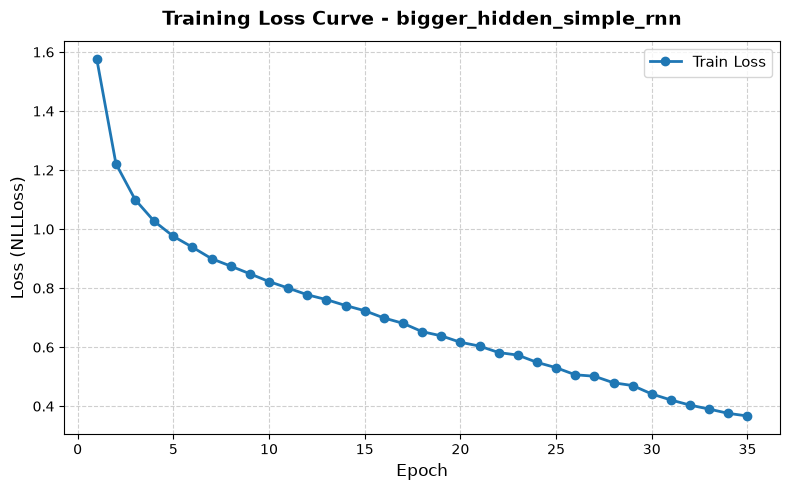

Loss curve saved to 'figures/bigger_hidden_simple_rnn/loss_curve.png'
Metrics saved to 'checkpoints/bigger_hidden_simple_rnn/metrics.json'


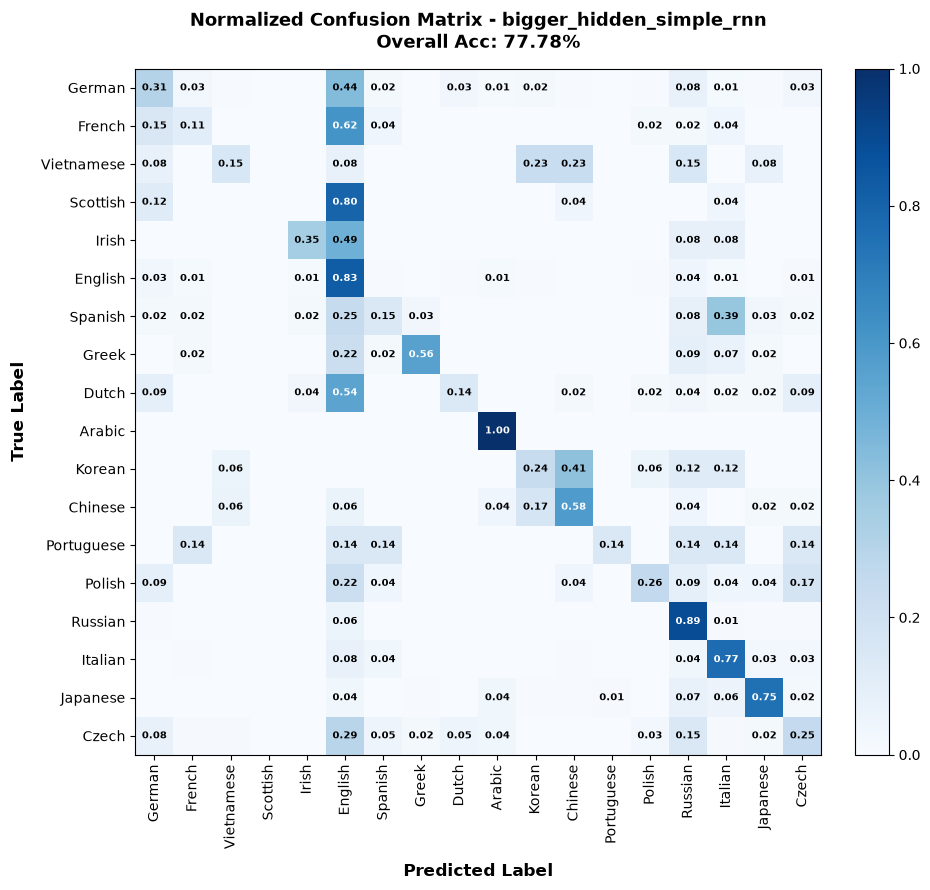

Confusion matrix saved to 'figures/bigger_hidden_simple_rnn/confusion_matrix.png'

       Running Experiment: more_hidden_simple_rnn
Training [more_hidden_simple_rnn] on dataset (n = 16060) using device: mps
Epoch 3/40 (8%) | Time: 73.06s | Average Loss: 1.1056
Epoch 6/40 (15%) | Time: 145.64s | Average Loss: 0.9289
Epoch 9/40 (22%) | Time: 218.18s | Average Loss: 0.8360
Epoch 12/40 (30%) | Time: 290.57s | Average Loss: 0.7603
Epoch 15/40 (38%) | Time: 363.25s | Average Loss: 0.6795
Epoch 18/40 (45%) | Time: 434.91s | Average Loss: 0.6107
Epoch 21/40 (52%) | Time: 506.55s | Average Loss: 0.5526
Epoch 24/40 (60%) | Time: 578.12s | Average Loss: 0.4950
Epoch 27/40 (68%) | Time: 649.95s | Average Loss: 0.4471
Epoch 30/40 (75%) | Time: 722.11s | Average Loss: 0.3994
Epoch 33/40 (82%) | Time: 794.24s | Average Loss: 0.3457
Epoch 36/40 (90%) | Time: 866.50s | Average Loss: 0.3058
Epoch 39/40 (98%) | Time: 938.18s | Average Loss: 0.2592
Epoch 40/40 (100%) | Time: 962.00s | Average Loss: 0.254

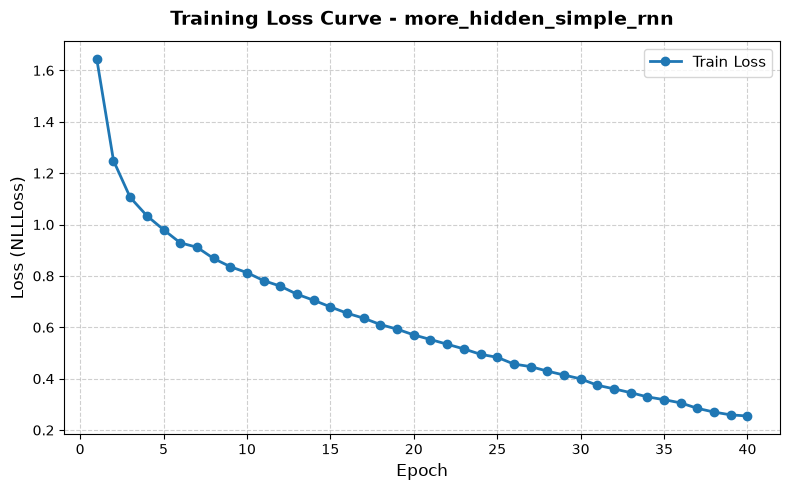

Loss curve saved to 'figures/more_hidden_simple_rnn/loss_curve.png'
Metrics saved to 'checkpoints/more_hidden_simple_rnn/metrics.json'


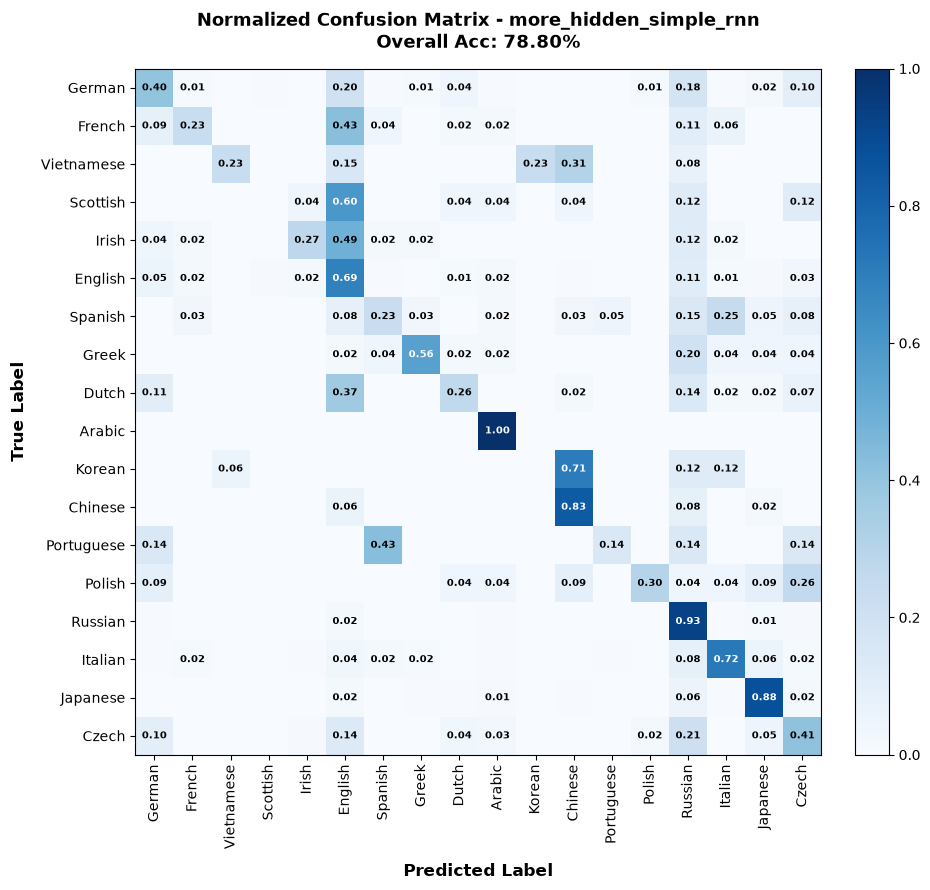

Confusion matrix saved to 'figures/more_hidden_simple_rnn/confusion_matrix.png'

       Running Experiment: small_gru_rnn
Training [small_gru_rnn] on dataset (n = 16060) using device: mps
Epoch 3/35 (9%) | Time: 52.49s | Average Loss: 1.3443
Epoch 6/35 (17%) | Time: 104.91s | Average Loss: 1.0983
Epoch 9/35 (26%) | Time: 157.69s | Average Loss: 0.9807
Epoch 12/35 (34%) | Time: 210.67s | Average Loss: 0.9137
Epoch 15/35 (43%) | Time: 263.31s | Average Loss: 0.8697
Epoch 18/35 (51%) | Time: 316.10s | Average Loss: 0.8159
Epoch 21/35 (60%) | Time: 369.22s | Average Loss: 0.7670
Epoch 24/35 (69%) | Time: 422.34s | Average Loss: 0.7313
Epoch 27/35 (77%) | Time: 475.59s | Average Loss: 0.6893
Epoch 30/35 (86%) | Time: 529.17s | Average Loss: 0.6550
Epoch 33/35 (94%) | Time: 582.07s | Average Loss: 0.6183
Epoch 35/35 (100%) | Time: 617.25s | Average Loss: 0.5963

Training complete! Checkpoints saved to 'checkpoints/small_gru_rnn/'


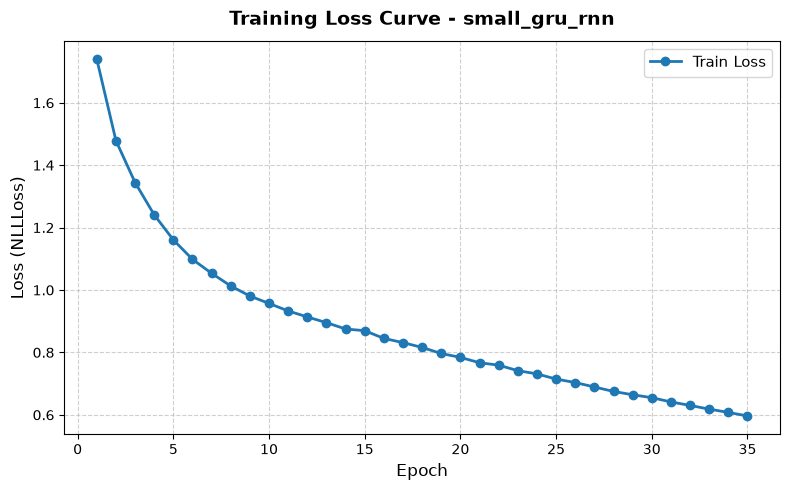

Loss curve saved to 'figures/small_gru_rnn/loss_curve.png'
Metrics saved to 'checkpoints/small_gru_rnn/metrics.json'


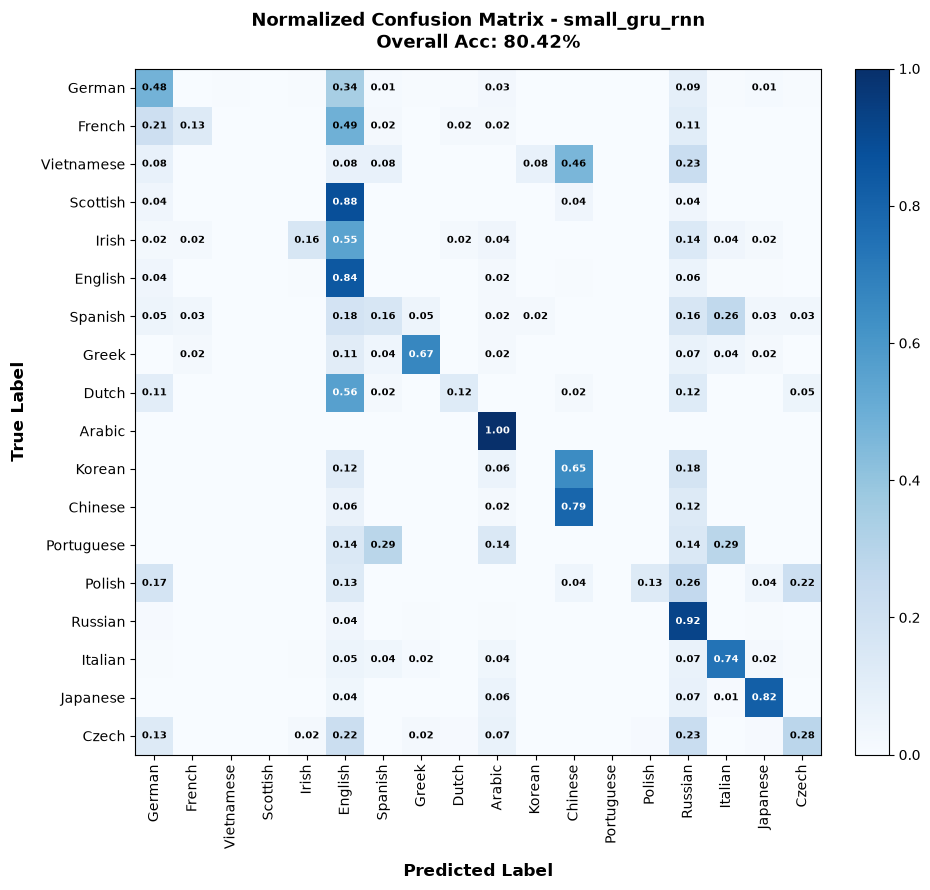

Confusion matrix saved to 'figures/small_gru_rnn/confusion_matrix.png'

       Running Experiment: big_gru_rnn
Training [big_gru_rnn] on dataset (n = 16060) using device: mps
Epoch 3/45 (7%) | Time: 102.25s | Average Loss: 1.5019
Epoch 6/45 (13%) | Time: 204.63s | Average Loss: 1.2850
Epoch 9/45 (20%) | Time: 307.41s | Average Loss: 1.1499
Epoch 12/45 (27%) | Time: 410.14s | Average Loss: 1.0368
Epoch 15/45 (33%) | Time: 512.84s | Average Loss: 0.9642
Epoch 18/45 (40%) | Time: 615.75s | Average Loss: 0.9135
Epoch 21/45 (47%) | Time: 718.94s | Average Loss: 0.8743
Epoch 24/45 (53%) | Time: 821.69s | Average Loss: 0.8421
Epoch 27/45 (60%) | Time: 924.45s | Average Loss: 0.8183
Epoch 30/45 (67%) | Time: 1027.31s | Average Loss: 0.7918
Epoch 33/45 (73%) | Time: 1130.01s | Average Loss: 0.7647
Epoch 36/45 (80%) | Time: 1232.86s | Average Loss: 0.7395
Epoch 39/45 (87%) | Time: 1335.62s | Average Loss: 0.7150
Epoch 42/45 (93%) | Time: 1438.55s | Average Loss: 0.6886
Epoch 45/45 (100%) | Time:

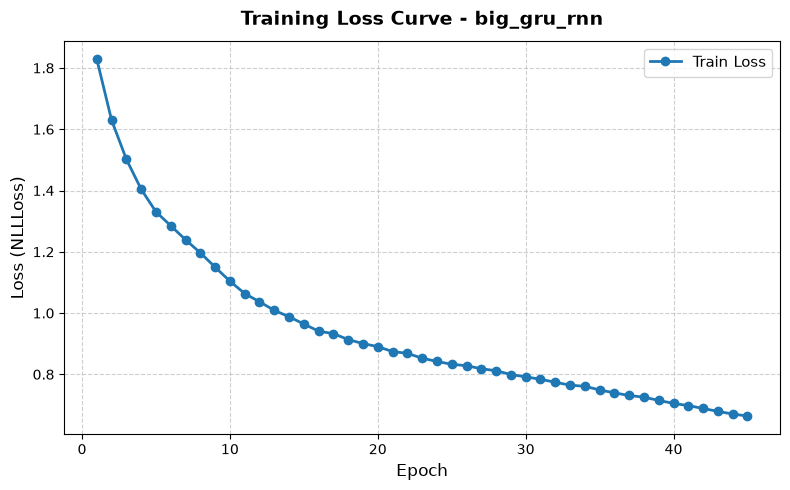

Loss curve saved to 'figures/big_gru_rnn/loss_curve.png'
Metrics saved to 'checkpoints/big_gru_rnn/metrics.json'


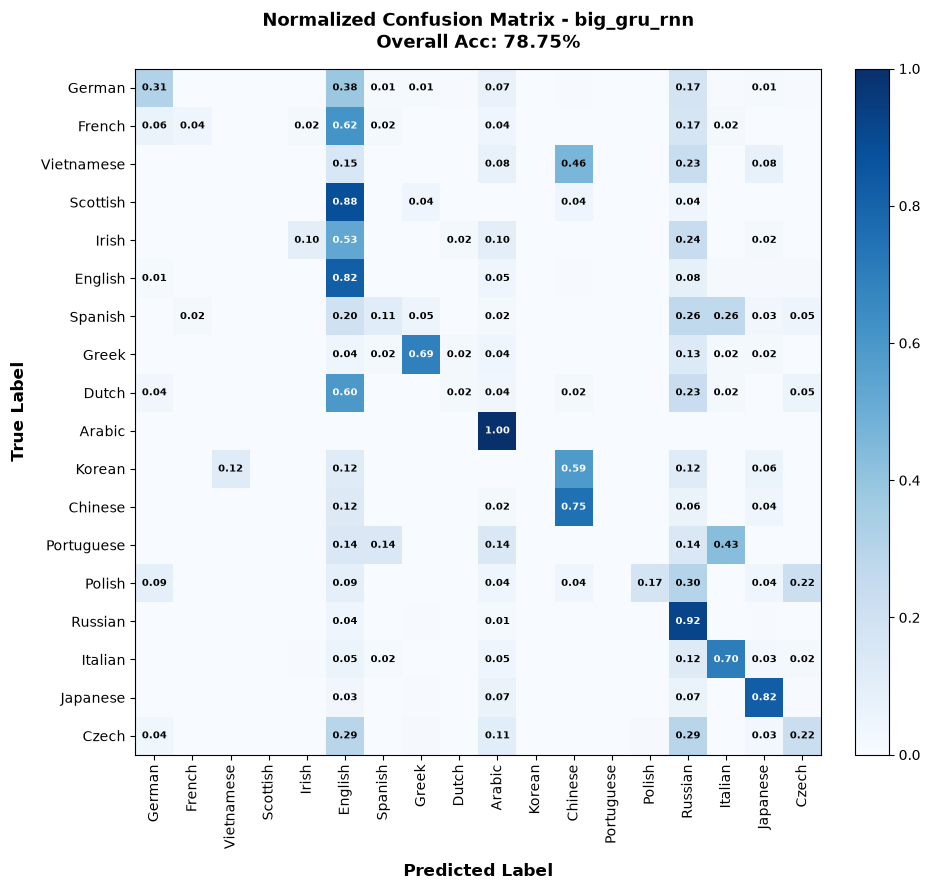

Confusion matrix saved to 'figures/big_gru_rnn/confusion_matrix.png'

       Running Experiment: small_lstm_rnn
Training [small_lstm_rnn] on dataset (n = 16060) using device: mps
Epoch 3/35 (9%) | Time: 20.54s | Average Loss: 1.5190
Epoch 6/35 (17%) | Time: 40.27s | Average Loss: 1.2775
Epoch 9/35 (26%) | Time: 60.06s | Average Loss: 1.1014
Epoch 12/35 (34%) | Time: 79.90s | Average Loss: 0.9978
Epoch 15/35 (43%) | Time: 99.66s | Average Loss: 0.9200
Epoch 18/35 (51%) | Time: 119.46s | Average Loss: 0.8574
Epoch 21/35 (60%) | Time: 139.29s | Average Loss: 0.8041
Epoch 24/35 (69%) | Time: 159.05s | Average Loss: 0.7654
Epoch 27/35 (77%) | Time: 178.88s | Average Loss: 0.7174
Epoch 30/35 (86%) | Time: 198.72s | Average Loss: 0.6833
Epoch 33/35 (94%) | Time: 218.50s | Average Loss: 0.6404
Epoch 35/35 (100%) | Time: 231.70s | Average Loss: 0.6249

Training complete! Checkpoints saved to 'checkpoints/small_lstm_rnn/'


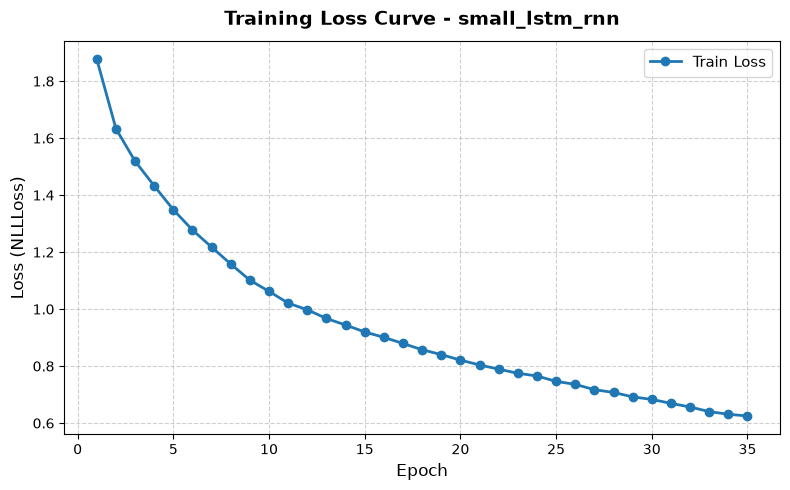

Loss curve saved to 'figures/small_lstm_rnn/loss_curve.png'
Metrics saved to 'checkpoints/small_lstm_rnn/metrics.json'


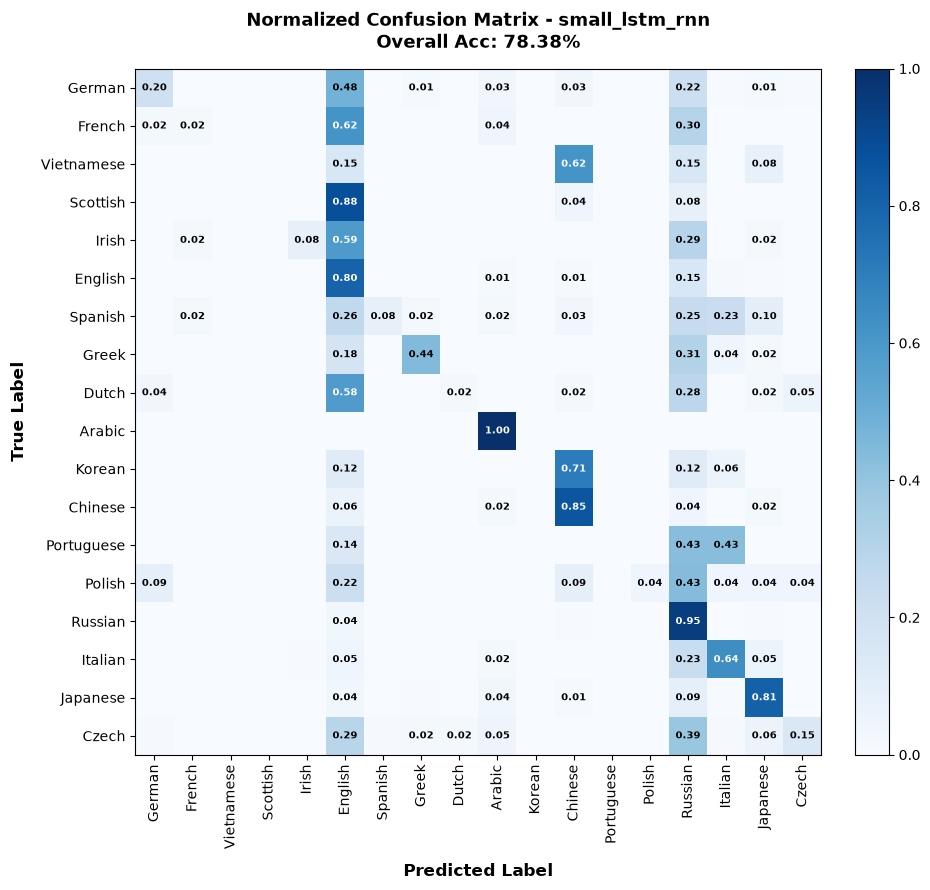

Confusion matrix saved to 'figures/small_lstm_rnn/confusion_matrix.png'

       Running Experiment: big_lstm_rnn
Training [big_lstm_rnn] on dataset (n = 16060) using device: mps
Epoch 3/50 (6%) | Time: 31.98s | Average Loss: 1.7218
Epoch 6/50 (12%) | Time: 63.56s | Average Loss: 1.6234
Epoch 9/50 (18%) | Time: 95.20s | Average Loss: 1.4925
Epoch 12/50 (24%) | Time: 126.17s | Average Loss: 1.3652
Epoch 15/50 (30%) | Time: 157.05s | Average Loss: 1.2715
Epoch 18/50 (36%) | Time: 188.04s | Average Loss: 1.2075
Epoch 21/50 (42%) | Time: 219.03s | Average Loss: 1.1363
Epoch 24/50 (48%) | Time: 250.03s | Average Loss: 1.0593
Epoch 27/50 (54%) | Time: 281.00s | Average Loss: 1.0083
Epoch 30/50 (60%) | Time: 312.05s | Average Loss: 0.9750
Epoch 33/50 (66%) | Time: 343.03s | Average Loss: 0.9477
Epoch 36/50 (72%) | Time: 374.14s | Average Loss: 0.9158
Epoch 39/50 (78%) | Time: 405.21s | Average Loss: 0.8874
Epoch 42/50 (84%) | Time: 436.35s | Average Loss: 0.8628
Epoch 45/50 (90%) | Time: 467.4

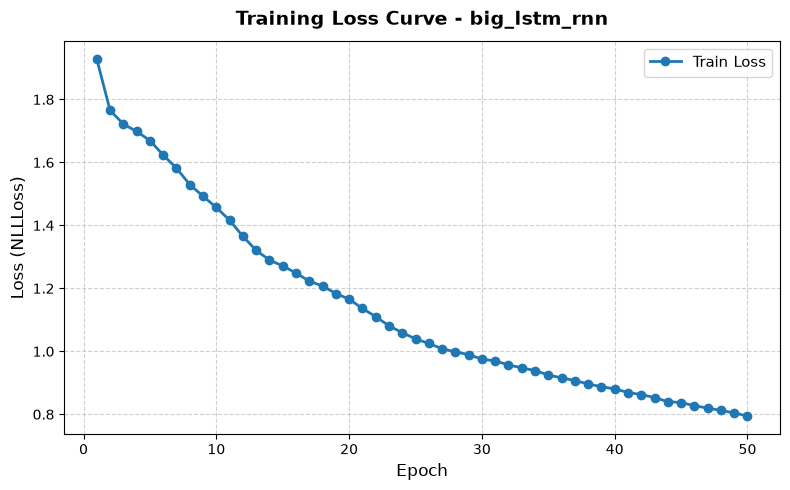

Loss curve saved to 'figures/big_lstm_rnn/loss_curve.png'
Metrics saved to 'checkpoints/big_lstm_rnn/metrics.json'


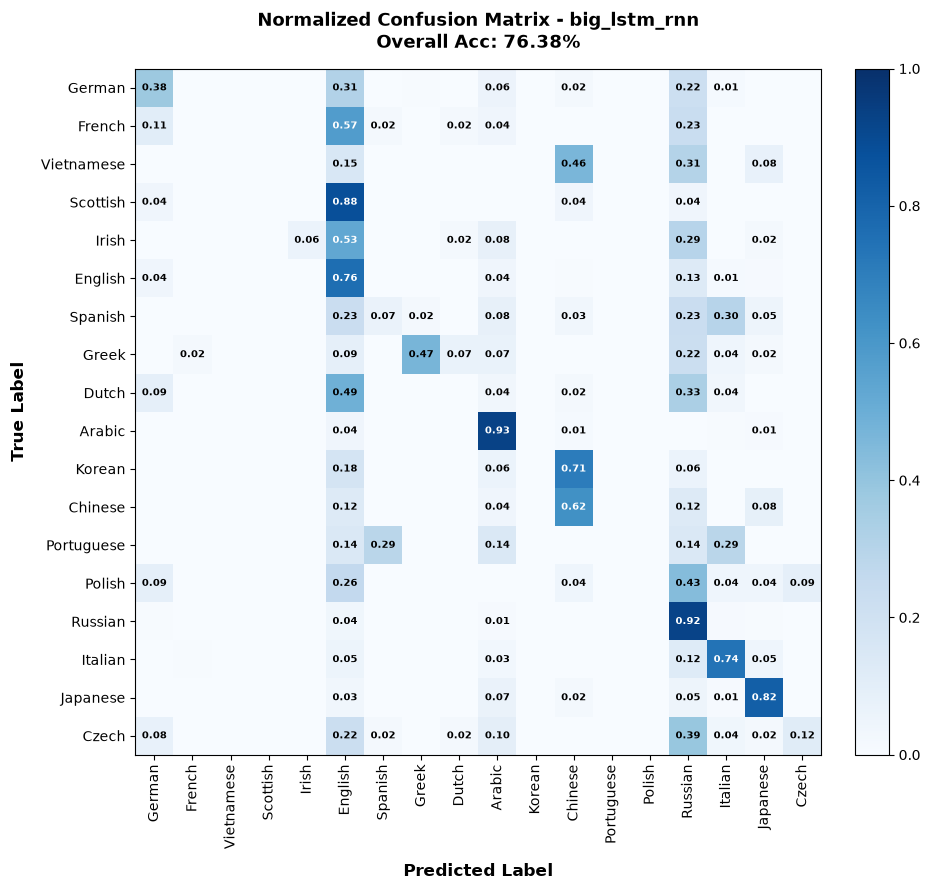

Confusion matrix saved to 'figures/big_lstm_rnn/confusion_matrix.png'


In [43]:
experiments = [
    {
        "name": "bigger_hidden_simple_rnn",
        "model": bigger_hidden_simple_rnn,
        "lr": 0.15,
        "epochs": 35
    },
    {
        "name": "more_hidden_simple_rnn",
        "model": more_hidden_simple_rnn,
        "lr": 0.10,
        "epochs": 40
    },
    {
        "name": "small_gru_rnn",
        "model": small_gru_rnn,
        "lr": 0.15,
        "epochs": 35
    },
    {
        "name": "big_gru_rnn",
        "model": big_gru_rnn,
        "lr": 0.10,
        "epochs": 45
    },
    {
        "name": "small_lstm_rnn",
        "model": small_lstm_rnn,
        "lr": 0.15,
        "epochs": 35
    },
    {
        "name": "big_lstm_rnn",
        "model": big_lstm_rnn,
        "lr": 0.10,
        "epochs": 50
    }
]

# Automated loop to train and evaluate all experiments
for exp in experiments:
    m_name = exp["name"]
    model = exp["model"].to(device)

    print(f"\n==========================================")
    print(f"       Running Experiment: {m_name}")
    print(f"==========================================")

    checkpoint_path = os.path.join('checkpoints', m_name, 'best_model.pt')

    # Trains or loads the model from checkpoint if available
    if os.path.exists(checkpoint_path) and not force_train:
        print(f"Loading cached model from '{checkpoint_path}'...")
        checkpoint = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(checkpoint['model_state_dict'])
        losses = checkpoint['all_losses']
    else:
        losses = train(
            rnn=model,
            training_data=train_set,
            model_name=m_name,
            n_epoch=exp["epochs"],
            learning_rate=exp["lr"],
            report_every=3,
            device=device
        )

    # Generates and saves the loss curve and evaluation metrics
    plot_loss_curve(losses, model_name=m_name)
    evaluate(model, test_set, alldata.labels_uniq, model_name=m_name, device=device)

## Comparing results

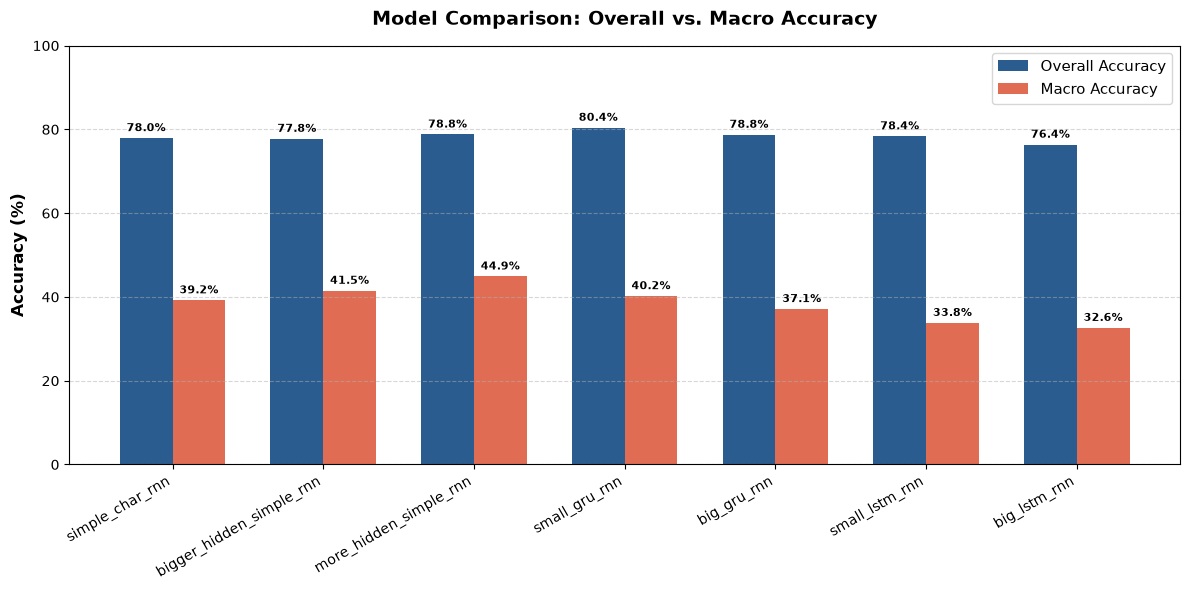

Comparison chart saved to 'figures/comparison/overall_vs_macro.png'


In [44]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Consolidação dos dados de todos os 7 modelos
results = {
    "simple_char_rnn": {"overall": 0.7795, "macro": 0.3923},
    "bigger_hidden_simple_rnn": {"overall": 0.7778, "macro": 0.4151},
    "more_hidden_simple_rnn": {"overall": 0.7880, "macro": 0.4492},
    "small_gru_rnn": {"overall": 0.8042, "macro": 0.4022},
    "big_gru_rnn": {"overall": 0.7875, "macro": 0.3714},
    "small_lstm_rnn": {"overall": 0.7838, "macro": 0.3382},
    "big_lstm_rnn": {"overall": 0.7638, "macro": 0.3264}
}

model_names = list(results.keys())
overall_accs = [results[m]["overall"] for m in model_names]
macro_accs = [results[m]["macro"] for m in model_names]

output_dir = "figures/comparison"
os.makedirs(output_dir, exist_ok=True)

# --- Gráfico 1: Overall Acc vs Macro Acc ---
plt.figure(figsize=(12, 6))
x = np.arange(len(model_names))
width = 0.35

rects1 = plt.bar(x - width/2, [v * 100 for v in overall_accs], width, label='Overall Accuracy', color='#2b5c8f')
rects2 = plt.bar(x + width/2, [v * 100 for v in macro_accs], width, label='Macro Accuracy', color='#e06d53')

plt.ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
plt.title('Model Comparison: Overall vs. Macro Accuracy', fontsize=14, fontweight='bold', pad=15)
plt.xticks(x, model_names, rotation=30, ha='right', fontsize=10)
plt.ylim(0, 100)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Adiciona valores sobre as barras
for rect in rects1:
    height = rect.get_height()
    plt.annotate(f'{height:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')

for rect in rects2:
    height = rect.get_height()
    plt.annotate(f'{height:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'overall_vs_macro.png'), dpi=300)
plt.show()

print(f"Comparison chart saved to '{output_dir}/overall_vs_macro.png'")

### 📊 Comparative Analysis & Discussion on RNN Architectures

After evaluating 7 model variations across **Vanilla RNN**, **GRU**, and **LSTM** architectures with different hidden dimensions and layer counts, we synthesized our empirical findings to answer the core exercise questions.

---

#### 1. Summary of Experimental Results

| Model Name | Architecture | Hidden Units | Num Layers | Overall Acc (%) | Macro Acc (%) | Best Performing Aspect / Trade-off |
| :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| `simple_char_rnn` | Vanilla RNN | 128 | 1 | 77.95% | 39.23% | Baseline model |
| `bigger_hidden_simple_rnn` | Vanilla RNN | 256 | 1 | 77.78% | 41.51% | Better minority retention than baseline |
| **`more_hidden_simple_rnn`** | **Vanilla RNN** | **256** | **2** | **78.80%** | **44.92%** | **Highest Macro Accuracy (Best Class Balance)** |
| **`small_gru_rnn`** | **GRU** | **128** | **1** | **80.42%** | **40.22%** | **Highest Overall Accuracy** |
| `big_gru_rnn` | GRU | 256 | 2 | 78.75% | 37.14% | Overfits majority classes, collapses minority |
| `small_lstm_rnn` | LSTM | 128 | 1 | 78.38% | 33.82% | Poor retention on minority classes |
| `big_lstm_rnn` | LSTM | 256 | 2 | 76.38% | 32.64% | Worst performance across both metrics |

---

#### 2. Discussion & Answers to Exercise Questions

##### ❓ Question 1 & 4: Alternative Recurrent Layers (`nn.LSTM` vs `nn.GRU` vs Vanilla RNN)
* **Finding:** Switching to **GRU** (`small_gru_rnn`) achieved the **highest Overall Accuracy (80.42%)** among all tested models. However, **LSTM performed worse than both GRU and Vanilla RNN** across the board (`big_lstm_rnn` dropped to 76.38% Overall Acc).
* **Why did this happen?**
  1. **Sequence Length:** Character-level surnames are short sequences (average length of 6–10 characters). The long-term memory gating mechanisms of LSTMs (cell state, forget gate, input gate) are engineered for long sequences. On short strings, the extra parameters provide diminishing returns.
  2. **Over-parameterization & Class Imbalance:** LSTMs have $4\times$ and GRUs have $3\times$ the parameter count of Vanilla RNNs. Due to extreme class imbalance in the dataset (e.g., Russian = 1,902 samples vs. Vietnamese = 13 samples), complex gated models easily overfit on majority classes (predicting Russian/Arabic/English with near 100% accuracy) while completely collapsing to **0.0% accuracy** on small minority classes (Scottish, Vietnamese, Portuguese, Korean).

---

##### ❓ Question 2 & 5: Adjusting Layer Dimensions (`hidden_size`) & Hyperparameters
* **Finding:**
  * For **Vanilla RNN**, increasing `hidden_size` from 128 to 256 (`bigger_hidden_simple_rnn`) improved Macro Accuracy from **39.23% to 41.51%** without degrading Overall Accuracy.
  * For **GRU and LSTM**, increasing `hidden_size` from 128 to 256 **degraded Macro Accuracy significantly** (GRU: $40.22\% \rightarrow 37.14\%$; LSTM: $33.82\% \rightarrow 32.64\%$).
* **Takeaway:** Increasing capacity in gated recurrent layers without class-rebalancing techniques (e.g., Weighted Cross-Entropy or Focal Loss) encourages the network to sacrifice rare classes to minimize global loss faster.

---

##### ❓ Question 3: Adding More Recurrent Layers (`num_layers = 2`)
* **Finding:** 
  * In Vanilla RNNs, stacking 2 layers (`more_hidden_simple_rnn`) produced the **highest Macro Accuracy of all experiments (44.92%)**. The extra layer allowed the network to learn hierarchical character combinations (e.g., language-specific suffixes/prefixes) without over-parameterizing the temporal step.
  * In GRU and LSTM, stacking 2 layers **reduced performance across both metrics**. The added depth introduced vanishing/exploding gradient friction during backpropagation through time (BTT) on small minibatches, despite using dropout.

---

#### 3. Key Conclusions & Recommendations

1. **Winning Model for Class Balance:** **`more_hidden_simple_rnn`** (Vanilla RNN, 256 hidden units, 2 layers). It provides the most balanced predictions across all 18 nationalities.
2. **Winning Model for Raw Accuracy:** **`small_gru_rnn`** (GRU, 128 hidden units, 1 layer). Best if maximum overall accuracy is the primary objective.
3. **Core Insight:** More complex models (LSTM/Deep GRU) are not inherently better for every sequential problem. For short character sequences with severe class imbalance, simpler architectures with increased depth or capacity retain minority feature patterns more effectively than heavily gated units.